# 01 · Dữ liệu IWSLT'15 Anh–Việt & Tokenizer SentencePiece

**Dữ liệu:** IWSLT'15 English–Vietnamese (phụ đề TED Talks), split chuẩn trong các bài báo:
train ≈133k cặp câu · dev = **tst2012** (1.553 câu) · test = **tst2013** (1.268 câu).

**Các rủi ro đã được xử lý trong code:**
| Rủi ro | Cách xử lý |
|---|---|
| Bộ `mt_eng_vietnamese` trên Hugging Face có validation **trùng** test (đều tst2013) | Lấy dev = tst2012 từ nguồn Stanford; nếu phải dùng nguồn HF thì tách dev từ train. Có bước tự kiểm tra rò rỉ dev/test |
| Văn bản gốc đã bị tách token kiểu Moses và mã hoá HTML (`it &apos;s`) | Giải mã HTML + ghép token (detokenize) → văn bản tự nhiên, để mô hình train từ đầu và pretrained được chấm trên cùng dạng văn bản |
| Tiếng Việt có 2 dạng mã hoá Unicode (dựng sẵn / tổ hợp) | Chuẩn hoá NFC cho nguồn, tham chiếu và bản dịch |
| Câu trùng lặp, câu quá dài, cặp lệch độ dài, câu test lọt vào train | Lọc trên **train** (dev/test giữ nguyên để so sánh được với công trình khác) |
| Token `<unk>` khi gặp ký tự hiếm | SentencePiece BPE có `byte_fallback` |

> **Quy trình chống lỗi:** luôn chạy với `DRY_RUN = True` trước (vài phút, dữ liệu và mô hình tí hon, đi qua **mọi**
> dòng code). Khi không còn lỗi nào, đổi `DRY_RUN = False` rồi chọn **Runtime → Run all** để chạy thật.
> Kết quả chạy thử nằm riêng trong thư mục `dryrun/`, không lẫn với kết quả thật.

In [12]:
#@title ⚙️ Tham số
DRY_RUN = False          # True: tokenizer nhỏ để chạy thử nhanh các notebook sau
VOCAB_SIZE = 16000      # từ vựng BPE chung Anh-Việt (bản thật)
DATA_SOURCE = "auto"    # "auto" | "stanford" | "hf"
REBUILD_DATA = False    # True: làm sạch lại dữ liệu từ đầu
RETRAIN_SPM = False     # True: huấn luyện lại tokenizer

In [13]:
#@title 🔧 Kết nối Google Drive + nạp thư viện `envi_lib`
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
PROJECT_DIR = os.environ.get("ENVI_PROJECT_DIR", "/content/drive/MyDrive/NLP_Final_EnVi")
if not os.path.exists(os.path.join(PROJECT_DIR, "envi_lib", "__init__.py")):
    raise FileNotFoundError(f"Chưa có thư viện ở {PROJECT_DIR}/envi_lib — hãy chạy notebook 00_cai_dat.ipynb trước.")
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
from envi_lib.common import (Paths, set_seed, get_device, pick_amp_dtype, autocast_ctx, gpu_info, peak_gpu_mem_gb,
                             reset_peak_mem, free_memory, count_params, disk_free_gb, save_predictions,
                             prediction_is_current, save_json, load_json, read_lines, write_lines, fmt_seconds,
                             bf16_supported, check_lib_version, now_str)
check_lib_version("1.0.0")
paths = Paths(PROJECT_DIR, dry_run=DRY_RUN).make_all()
DEVICE = get_device()
print(f"📁 {paths.root}   |   DRY_RUN = {DRY_RUN}   |   thiết bị: {gpu_info()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 /content/drive/MyDrive/NLP_Final_EnVi   |   DRY_RUN = False   |   thiết bị: {'cuda': True, 'torch': '2.11.0+cu130', 'name': 'NVIDIA L4', 'total_gb': 22.0, 'bf16': True}


In [14]:
%pip install -q sacrebleu sacremoses sentencepiece
import random, numpy as np, pandas as pd, matplotlib.pyplot as plt
from envi_lib import data as D
pd.set_option("display.max_colwidth", 120)

## 1. Tải dữ liệu thô
Nếu máy chủ Stanford lỗi, có thể tự tải 6 file `train/tst2012/tst2013 .en/.vi` từ https://nlp.stanford.edu/projects/nmt/ rồi đặt vào `NLP_Final_EnVi/data_raw/stanford/`.

In [15]:
raw_info = D.fetch_raw(paths, DATA_SOURCE)
print(raw_info)
raw = D.load_raw(raw_info)
for split, (s, t) in raw.items():
    print(f"{split:5s}: {len(s):>7,} dòng")
print("\nVí dụ dữ liệu THÔ (chú ý &apos; &quot; và khoảng trắng trước dấu câu):")
for i in [i for i, x in enumerate(raw["train"][0][:3000]) if "&apos;" in x or "&quot;" in x][:3]:
    print("  EN:", raw["train"][0][i]); print("  VI:", raw["train"][1][i]); print()

⬇ Tải IWSLT'15 En-Vi từ Stanford NLP ...
   lần 1/3 lỗi khi tải https://nlp.stanford.edu/projects/nmt/data/iwslt15.en-vi/train.en: HTTP Error 403: Forbidden
   lần 2/3 lỗi khi tải https://nlp.stanford.edu/projects/nmt/data/iwslt15.en-vi/train.en: HTTP Error 403: Forbidden
   lần 3/3 lỗi khi tải https://nlp.stanford.edu/projects/nmt/data/iwslt15.en-vi/train.en: HTTP Error 403: Forbidden
⚠️  Không tải được từ Stanford (Không tải được https://nlp.stanford.edu/projects/nmt/data/iwslt15.en-vi/train.en: HTTP Error 403: Forbidden).
⬇ Dùng nguồn dự phòng Hugging Face (parquet) ...
ℹ️  Nguồn HF: tập dev sẽ được tách từ train (vì validation của HF trùng test).
{'source': 'hf', 'dir': '/content/drive/MyDrive/NLP_Final_EnVi/data_raw/hf', 'dev_from_train': True}
train: 133,317 dòng
test :   1,268 dòng

Ví dụ dữ liệu THÔ (chú ý &apos; &quot; và khoảng trắng trước dấu câu):
  EN: I &apos;d like to talk to you today about the scale of the scientific effort that goes into making the headlines you see i

## 2. Làm sạch & lọc

In [16]:
if REBUILD_DATA or not (paths.data_clean / "data_info.json").exists():
    info = D.build_clean_dataset(paths, raw_info)
else:
    info = load_json(paths.data_clean / "data_info.json")
    print("✔ Dùng dữ liệu sạch đã có (đặt REBUILD_DATA=True nếu muốn làm lại).")
print(f"Nguồn: {info['source']} | dev: {info['dev_name']} | test: {info['test_name']}")
print("Số cặp câu sau làm sạch:", info["counts"])
pd.DataFrame(info["clean_report"]).fillna(0).astype(int)

✔ Dùng dữ liệu sạch đã có (đặt REBUILD_DATA=True nếu muốn làm lại).
Nguồn: hf | dev: 1500 câu tách từ train | test: tst2013
Số cặp câu sau làm sạch: {'train': 130400, 'dev': 1500, 'test': 1268}


,train,dev,test
trùng câu nguồn dev/test,934,0,0
rỗng,151,0,0
dài > 150 từ,73,0,0
trùng lặp,218,0,0
tỉ lệ độ dài > 3.5,17,0,0
giữ lại,131924,0,1268
tách từ train,0,1500,0


In [17]:
train_src, train_tgt = D.load_clean(paths, "train")
dev_src, dev_tgt = D.load_clean(paths, "dev")
test_src, test_tgt = D.load_clean(paths, "test")
# Kiểm tra lại các bất biến quan trọng
if info["source"] == "stanford" and not (1250 <= len(test_src) <= 1270):
    print(f"⚠️  Tập test có {len(test_src)} câu (chuẩn tst2013: 1.268) — kiểm tra lại file tải về.")
D.check_no_leakage(train_src, dev_src, test_src, dev_tgt, test_tgt)
assert not any("&apos;" in x or "&quot;" in x for x in train_src[:20000] + train_tgt[:20000])
print("Ví dụ sau làm sạch:")
rng = random.Random(1)
pd.DataFrame([{"en": train_src[i], "vi": train_tgt[i]} for i in rng.sample(range(len(train_src)), 5)])

✔ Kiểm tra rò rỉ: dev∩test = 0 cặp, train∩test(nguồn) = 0
Ví dụ sau làm sạch:


,en,vi
0,"It has internal inconsistencies, unless we allow for something wholly unfamiliar -- extra dimensions of space.","Nó có nhiều mâu thuẫn, trừ khi ta chấp nhận một thứ hoàn toàn xa lạ -- những chiều khác của không gian."
1,"He's a multi-millionaire, and I think that's why he's smiling in this photograph.","Ông ấy là triệu phú, và tôi nghĩ đó là lí do vì sao ông ấy cười trong tấm hình này"
2,"So we had our own miniature rainforest, a private beach with a coral reef.","Chúng tôi chỉ có 1 rừng mưa thu nhỏ, 1 bãi biển riêng với 1 dãi san hô."
3,"All right, second line.","Được rồi, hàng thứ hai."
4,"But I don't need to tell you this, let's throw it back to him.","Nhưng tôi khỏi cần nói với bạn điều đó, chúng ta hãy quay lại với anh ấy."


## 3. Thống kê dữ liệu (EDA)

In [18]:
rows = []
for split, (s, t) in {"train": (train_src, train_tgt), "dev": (dev_src, dev_tgt), "test": (test_src, test_tgt)}.items():
    for lang, lines in (("en", s), ("vi", t)):
        st = D.length_stats(lines)
        vocab = len({w for l in lines for w in l.lower().split()})
        rows.append({"split": split, "ngôn ngữ": lang, "số câu": st["n"], "TB từ/câu": round(st["mean"], 1),
                     "trung vị": st["median"], "p95": st["p95"], "max": st["max"], "số từ khác nhau": vocab})
eda = pd.DataFrame(rows)
eda.to_csv(paths.results / "eda_length_stats.csv", index=False)
eda

,split,ngôn ngữ,số câu,TB từ/câu,trung vị,p95,max,số từ khác nhau
0,train,en,130400,17.4,14.0,42.00,140,92133
1,train,vi,130400,22.7,18.0,54.00,150,43299
2,dev,en,1500,17.4,14.0,41.00,90,6351
3,dev,vi,1500,22.8,19.0,53.00,129,4050
4,test,en,1268,18.1,15.0,42.65,93,5017
5,test,vi,1268,24.1,20.0,56.00,118,3448


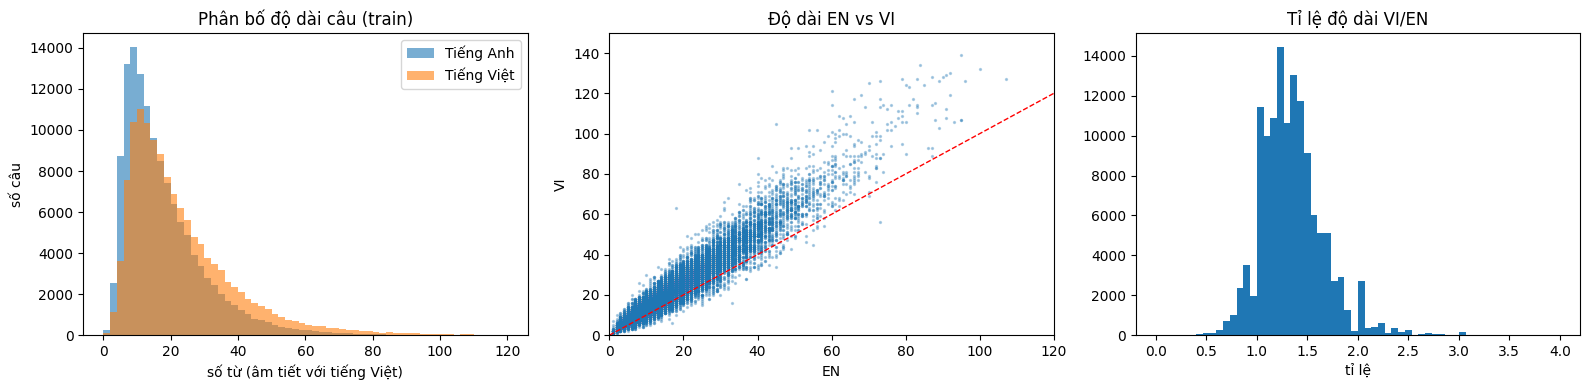

Tỉ lệ độ dài VI/EN trung bình: 1.34  (tiếng Việt tách theo âm tiết nên dài hơn)


In [19]:
len_en = np.array([len(x.split()) for x in train_src]); len_vi = np.array([len(x.split()) for x in train_tgt])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(len_en, bins=60, range=(0, 120), alpha=.6, label="Tiếng Anh"); ax[0].hist(len_vi, bins=60, range=(0, 120), alpha=.6, label="Tiếng Việt")
ax[0].set(title="Phân bố độ dài câu (train)", xlabel="số từ (âm tiết với tiếng Việt)", ylabel="số câu"); ax[0].legend()
ax[1].scatter(len_en[:20000], len_vi[:20000], s=2, alpha=.3); ax[1].plot([0, 120], [0, 120], "r--", lw=1)
ax[1].set(title="Độ dài EN vs VI", xlabel="EN", ylabel="VI", xlim=(0, 120), ylim=(0, 150))
ax[2].hist(len_vi / np.maximum(1, len_en), bins=60, range=(0, 4)); ax[2].set(title="Tỉ lệ độ dài VI/EN", xlabel="tỉ lệ")
plt.tight_layout(); plt.savefig(paths.figures / "eda_lengths.png", dpi=150); plt.show()
print(f"Tỉ lệ độ dài VI/EN trung bình: {np.mean(len_vi / np.maximum(1, len_en)):.2f}  (tiếng Việt tách theo âm tiết nên dài hơn)")

In [20]:
from collections import Counter
top = {lang: Counter(w for l in lines for w in l.lower().split()).most_common(20)
       for lang, lines in (("en", train_src), ("vi", train_tgt))}
pd.DataFrame({"EN": [f"{w} ({c:,})" for w, c in top["en"]], "VI": [f"{w} ({c:,})" for w, c in top["vi"]]})

,EN,VI
0,"the (107,465)","và (65,109)"
1,"and (77,583)","tôi (58,060)"
2,"to (64,425)","là (55,034)"
3,"of (59,167)","một (50,687)"
4,"a (54,265)","có (49,271)"
5,"that (39,974)","chúng (43,407)"
6,"in (39,949)","những (39,406)"
7,"i (34,324)","của (36,378)"
8,"is (31,227)","không (28,431)"
9,"you (28,957)","ta (27,662)"


## 4. Tokenizer SentencePiece (BPE) cho 2 mô hình train từ đầu
- Từ vựng **chung** Anh–Việt (joint BPE) → cho phép dùng chung embedding giữa encoder, decoder và lớp đầu ra.
- Các mô hình pretrained (notebook 04, 05) dùng tokenizer riêng của chúng.

In [21]:
vocab = 2000 if DRY_RUN else VOCAB_SIZE
if RETRAIN_SPM or not paths.spm_model.exists():
    n_spm = 5000 if DRY_RUN else len(train_src)
    tok = D.train_spm(paths, train_src[:n_spm], train_tgt[:n_spm], vocab_size=vocab)
    print(f"✔ Đã huấn luyện tokenizer: {paths.spm_model}")
else:
    tok = D.SpmTokenizer(paths.spm_model)
    print(f"✔ Dùng tokenizer đã có: {paths.spm_model}")
print("Kích thước từ vựng:", tok.vocab_size, "| <pad>,<unk>,<s>,</s>,<sep> =", tok.pad_id, tok.unk_id, tok.bos_id, tok.eos_id, tok.sep_id)

# Kiểm tra: mã hoá -> giải mã phải khôi phục đúng câu; không có <unk>
sample = dev_src[:500] + dev_tgt[:500]
ids = tok.encode(sample)
rt = tok.decode(ids)
n_bad = sum(a != b for a, b in zip(rt, sample))
n_unk = sum(x.count(tok.unk_id) for x in ids)
print(f"Khôi phục sai: {n_bad}/{len(sample)} câu | số token <unk>: {n_unk}")
assert n_unk == 0, "Có <unk> — kiểm tra byte_fallback"
assert n_bad <= 0.01 * len(sample), "Tokenizer không khôi phục được câu gốc"
ex = "Tôi đã nói chuyện với các nhà khoa học về biến đổi khí hậu."
print("\nVí dụ tách từ:", tok.sp.encode(ex, out_type=str))
print("Ví dụ tách từ:", tok.sp.encode("It's a climate scientist's job.", out_type=str))

✔ Đã huấn luyện tokenizer: /content/drive/MyDrive/NLP_Final_EnVi/spm/spm_envi.model
Kích thước từ vựng: 16000 | <pad>,<unk>,<s>,</s>,<sep> = 0 1 2 3 4
Khôi phục sai: 0/1000 câu | số token <unk>: 0

Ví dụ tách từ: ['▁Tôi', '▁đã', '▁nói', '▁chuyện', '▁với', '▁các', '▁nhà', '▁khoa', '▁học', '▁về', '▁biến', '▁đổi', '▁khí', '▁hậu', '.']
Ví dụ tách từ: ['▁It', "'", 's', '▁a', '▁climate', '▁scientist', "'", 's', '▁job', '.']


In [22]:
tl_en = np.array([len(x) for x in tok.encode(train_src)]); tl_vi = np.array([len(x) for x in tok.encode(train_tgt)])
MAX_TOK = 150
over = np.mean((tl_en > MAX_TOK) | (tl_vi > MAX_TOK))
summary = {"vocab_size": tok.vocab_size, "tokens_per_sent_en": float(tl_en.mean()), "tokens_per_sent_vi": float(tl_vi.mean()),
           "p99_tokens_en": float(np.percentile(tl_en, 99)), "p99_tokens_vi": float(np.percentile(tl_vi, 99)),
           "ratio_pairs_over_150_tokens": float(over), "data": info}
save_json(summary, paths.results / "data_summary.json")
print(f"Số token BPE/câu: EN {tl_en.mean():.1f} | VI {tl_vi.mean():.1f}  (p99: {np.percentile(tl_en, 99):.0f} / {np.percentile(tl_vi, 99):.0f})")
print(f"Tỉ lệ cặp câu dài hơn {MAX_TOK} token (sẽ bỏ khi huấn luyện): {over:.3%}")
print("\n✅ Xong notebook 01. Tiếp theo: 02_transformer_encoder_decoder.ipynb")

Số token BPE/câu: EN 22.7 | VI 25.7  (p99: 80 / 92)
Tỉ lệ cặp câu dài hơn 150 token (sẽ bỏ khi huấn luyện): 0.033%

✅ Xong notebook 01. Tiếp theo: 02_transformer_encoder_decoder.ipynb
